# ✂️ Phân Chia Bộ Dữ Liệu DDI Thành Tập Cố Định: `train`, `val`, `test_s0`, `test_s1`, `test_s2`
### Chuẩn Đánh Giá Toàn Diện (Transductive, Semi-Inductive & Fully-Inductive Settings)
---

### 📌 1. Bối Cảnh Bài Toán & Các Kịch Bản Đánh Giá ($S_0, S_1, S_2$)

Trong các bài toán dự đoán tương tác thuốc (Drug-Drug Interaction - DDI) bằng mô hình học máy và học sâu (GNNs, Deep Learning, Multimodal Transformers), một thách thức lớn trong thực tiễn lâm sàng là tính khái quát hóa đối với các loại thuốc mới xuất hiện (Emerging / Novel Drugs). Để đánh giá khách quan năng lực của mô hình, cộng đồng nghiên cứu (DDI-Bench, EmerGNN, Bioinformatics) đã chuẩn hóa 3 kịch bản kiểm thử:

1. **`test_s0` (Transductive / Warm-Start Setting):**
   - **Định nghĩa:** Cả 2 loại thuốc trong cặp tương tác $(u, v)$ đều đã từng xuất hiện trong tập huấn luyện (`train`), nhưng bản thân cặp tương tác này chưa từng được huấn luyện.
   - **Điều kiện toán học:** $u \in Drugs(train) \land v \in Drugs(train)$.
   - **Bản chất:** Đánh giá khả năng suy diễn liên kết truyền thống (Link Prediction) giữa các thực thể đã biết.

2. **`test_s1` (Semi-Inductive / Semi-Cold-Start Setting):**
   - **Định nghĩa:** Đúng 1 loại thuốc trong cặp tương tác đã từng xuất hiện trong tập huấn luyện, còn loại thuốc kia hoàn toàn mới (chưa từng xuất hiện trong `train`).
   - **Điều kiện toán học:** $(u \in Drugs(train) \land v \notin Drugs(train)) \lor (u \notin Drugs(train) \land v \in Drugs(train))$.
   - **Bản chất:** Mô phỏng kịch bản thực tiễn khi một loại thuốc mới được nghiên cứu/phát triển cần được đánh giá nguy cơ tương tác với kho thuốc hiện hành.

3. **`test_s2` (Fully-Inductive / Full-Cold-Start Setting):**
   - **Định nghĩa:** Cả 2 loại thuốc trong cặp tương tác $(u, v)$ đều là thuốc mới hoàn toàn (chưa từng xuất hiện trong tập huấn luyện).
   - **Điều kiện toán học:** $u \notin Drugs(train) \land v \notin Drugs(train)$.
   - **Bản chất:** Kịch bản kiểm thử khắt khe nhất (Zero-Shot / Emerging-Emerging Drug Interaction), đánh giá khả năng mô hình dựa thuần túy vào đặc trưng nội tại (Text descriptions, SMILES molecular structure) để suy luận.

| Tập Dữ Liệu | Tên Kịch Bản | Thuốc 1 ($u$) | Thuốc 2 ($v$) | Bản Chất Học Máy | Ứng Dụng Thực Tiễn |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **`train`** | Huấn Luyện | Đã biết ($V_{seen}$) | Đã biết ($V_{seen}$) | Đồ thị huấn luyện | Học biểu diễn đặc trưng và tương tác |
| **`val`** | Thẩm Định | Đã biết ($V_{seen}$) | Đã biết ($V_{seen}$) | Đánh giá Early Stopping | Tinh chỉnh siêu tham số không rò rỉ |
| **`test_s0`** | Transductive (Seen - Seen) | **Có trong Train** | **Có trong Train** | Khái quát cặp mới trên thuốc cũ | Dự đoán tương tác mới giữa 2 thuốc cũ |
| **`test_s1`** | Semi-Inductive (Seen - Unseen) | **1 thuốc có trong Train** | **1 thuốc KHÔNG có trong Train** | Khái quát 1 phía (Cold-Start) | Thuốc mới ra mắt tương tác với thuốc hiện có |
| **`test_s2`** | Fully-Inductive (Unseen - Unseen) | **KHÔNG có trong Train** | **KHÔNG có trong Train** | Khái quát 2 phía (Zero-Shot) | Hai thuốc mới nghiên cứu dùng kết hợp |

---

### 🎯 2. Mục Tiêu & Cấu Trúc Thực Hiện
Notebook này thực hiện phân chia cố định cho toàn bộ dự án mà **không sử dụng 5-fold cross-validation**:
1. `ddi_pairs.csv` (37,264 cặp tương tác thuốc qua 65 nhãn tương tác).
2. `drug_features.json` (572 bản ghi đặc trưng văn bản và hóa học của thuốc).

Các tệp dữ liệu cố định được tạo ra trong thư mục `data2/`:
- **`train.csv`**: Tập huấn luyện, đảm bảo 100% thuốc Seen ($V_{seen}$) đều có mặt.
- **`val.csv`**: Tập validation phục vụ Early Stopping.
- **`test_s0.csv`**: Tập kiểm thử Transductive (cả 2 thuốc đều có trong `train`).
- **`test_s1.csv`**: Tập kiểm thử Semi-Inductive (đúng 1 thuốc có trong `train`, 1 thuốc không).
- **`test_s2.csv`**: Tập kiểm thử Fully-Inductive (cả 2 thuốc đều không có trong `train`).
- **`drug_features_train.json`** & **`drug_features_unseen.json`**: Phân tách đặc trưng chống rò rỉ dữ liệu (Data Leakage).


In [1]:
import os
import sys
import json
import time
import random
import warnings
from pathlib import Path
from collections import Counter

# Cấu hình thư mục cache matplotlib
os.environ['MPLCONFIGDIR'] = '/tmp/matplotlib'

# Tải các thư viện bổ trợ từ cache uv nếu chưa có trong sys.path
archive_dir = os.path.expanduser('~/.cache/uv/archive-v0')
cached_pkgs = [
    'JNrUcOZoiz44ekNQC85BY',  # pandas 3.0.6
    'L4EZniLCVNIgD7rC_EeDB',  # seaborn 0.13.2
    '6vlYpBZPQ0EyRknkerViM',  # networkx 3.7
    'eI6iL9ZuXZerY_BGsfLpY',  # scikit-learn 1.8.0
]
for pkg in cached_pkgs:
    p = os.path.join(archive_dir, pkg)
    if os.path.isdir(p) and p not in sys.path:
        sys.path.insert(0, p)

for p in os.listdir(archive_dir):
    sub = os.path.join(archive_dir, p)
    if os.path.isdir(sub) and any(item.startswith(('joblib', 'threadpoolctl')) for item in os.listdir(sub)):
        if sub not in sys.path:
            sys.path.insert(0, sub)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')

# Thiết lập Random Seed cố định để tái lập 100% kết quả
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Cấu hình phong cách biểu đồ
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.titleweight'] = 'bold'

# Đường dẫn tài nguyên đầu vào và thư mục lưu trữ dữ liệu cố định
BASE_DIR = Path('/home/tuannoiuem/entrance_ddi_test')
DDI_PAIRS_PATH = BASE_DIR / 'ddi_pairs.csv'
DRUG_FEATURES_PATH = BASE_DIR / 'drug_features.json'
DATA2_DIR = BASE_DIR / 'data2'

# Khởi tạo thư mục đích lưu trữ các tệp cố định
os.makedirs(DATA2_DIR, exist_ok=True)

print("✓ Thiết lập môi trường thành công!")
print(f"  • Thư mục đích dữ liệu cố định: {DATA2_DIR}")
print(f"  • Random Seed: {SEED}")


✓ Thiết lập môi trường thành công!
  • Thư mục đích dữ liệu cố định: /home/tuannoiuem/entrance_ddi_test/data2
  • Random Seed: 42


## 1. Khảo Sát & Phân Tích Cấu Trúc Dữ Liệu Đầu Vào
Tải và kiểm tra tính toàn vẹn giữa hai nguồn dữ liệu:
- Bảng tương tác: `ddi_pairs.csv` (37,264 tương tác giữa các cặp thuốc).
- Từ điển đặc trưng: `drug_features.json` (572 thuốc với 5 trường văn bản y sinh và cấu trúc hóa học).


In [2]:
# Tải bảng dữ liệu tương tác thuốc
df_ddi = pd.read_csv(DDI_PAIRS_PATH)

# Tải từ điển đặc trưng thuốc
with open(DRUG_FEATURES_PATH, 'r', encoding='utf-8') as f:
    drug_features = json.load(f)

# Tập hợp thuốc duy nhất tham gia tương tác
drugs_in_pairs = sorted(list(set(df_ddi['drug1_id']).union(set(df_ddi['drug2_id']))))
drugs_in_features = sorted(list(drug_features.keys()))

# Phân tích mức độ phủ và các thuốc đơn lẻ (Isolated)
isolated_drugs = sorted(list(set(drugs_in_features) - set(drugs_in_pairs)))
missing_in_features = sorted(list(set(drugs_in_pairs) - set(drugs_in_features)))

# Tính bậc (Degree) của từng loại thuốc trong đồ thị tương tác
drug_degree = Counter(df_ddi['drug1_id']) + Counter(df_ddi['drug2_id'])

print("=== TỔNG QUAN DỮ LIỆU ĐẦU VÀO ===")
print(f"• Số lượng cặp tương tác thuốc (ddi_pairs.csv): {len(df_ddi):,} dòng")
print(f"• Số loại thuốc duy nhất trong các cặp tương tác: {len(drugs_in_pairs):,} loại")
print(f"• Số loại thuốc trong từ điển đặc trưng (drug_features.json): {len(drugs_in_features):,} loại")
print(f"• Số loại thuốc không có tương tác nào (Isolated drugs): {len(isolated_drugs)} ({isolated_drugs})")
print(f"• Số thuốc trong ddi_pairs bị thiếu đặc trưng: {len(missing_in_features)} (100% đầy đủ)")
print(f"• Số lượng nhãn tương tác (Classes): {df_ddi['label'].nunique()} nhãn")

print("\n=== PHÂN BỐ BẬC CỦA THUỐC TRONG ĐỒ THỊ ===")
deg_vals = list(drug_degree.values())
print(f"• Bậc trung bình: {np.mean(deg_vals):.1f} tương tác / thuốc")
print(f"• Trung vị bậc: {np.median(deg_vals):.1f} | Bậc nhỏ nhất: {min(deg_vals)} | Bậc lớn nhất: {max(deg_vals)}")

# Kiểm tra các thuốc có bậc cực thấp (Degree = 1)
deg1_drugs = [d for d, c in drug_degree.items() if c == 1]
print(f"\n• Các thuốc đặc biệt chỉ có ĐÚNG 1 tương tác (Degree = 1): {deg1_drugs}")
for d in deg1_drugs:
    p = df_ddi[(df_ddi['drug1_id'] == d) | (df_ddi['drug2_id'] == d)].iloc[0]
    partner = p['drug2_id'] if p['drug1_id'] == d else p['drug1_id']
    partner_name = p['drug2_name'] if p['drug1_id'] == d else p['drug1_name']
    d_name = p['drug1_name'] if p['drug1_id'] == d else p['drug2_name']
    print(f"  - Thuốc {d} ({d_name}) ⟷ {partner} ({partner_name}) [Nhãn {p['label']}]")


=== TỔNG QUAN DỮ LIỆU ĐẦU VÀO ===
• Số lượng cặp tương tác thuốc (ddi_pairs.csv): 37,264 dòng
• Số loại thuốc duy nhất trong các cặp tương tác: 570 loại
• Số loại thuốc trong từ điển đặc trưng (drug_features.json): 572 loại
• Số loại thuốc không có tương tác nào (Isolated drugs): 2 (['DB00130', 'DB01213'])
• Số thuốc trong ddi_pairs bị thiếu đặc trưng: 0 (100% đầy đủ)
• Số lượng nhãn tương tác (Classes): 65 nhãn

=== PHÂN BỐ BẬC CỦA THUỐC TRONG ĐỒ THỊ ===
• Bậc trung bình: 130.8 tương tác / thuốc
• Trung vị bậc: 121.0 | Bậc nhỏ nhất: 1 | Bậc lớn nhất: 421

• Các thuốc đặc biệt chỉ có ĐÚNG 1 tương tác (Degree = 1): ['DB00769', 'DB00134']
  - Thuốc DB00769 (Hydrocortamate) ⟷ DB01238 (Aripiprazole) [Nhãn 3]
  - Thuốc DB00134 (Methionine) ⟷ DB01235 (Levodopa) [Nhãn 4]


## 2. Thuật Toán Phân Chia Cố Định Bảo Toàn Cấu Trúc Đồ Thị
Để tạo ra các tập `train`, `val`, `test_s0`, `test_s1`, `test_s2` thỏa mãn 100% định nghĩa:
1. **Phân chia mức nút thuốc ($V_{seen}$ và $V_{unseen}$):**
   - 570 thuốc được chia thành 456 thuốc Seen (80%) và 114 thuốc Unseen (20%).
   - **Quy tắc bảo toàn thuốc đơn bậc:** Đối với 2 thuốc có bậc 1 (`DB00134` và `DB00769`), chúng bắt buộc phải được xếp cùng nhóm với bạn tương tác duy nhất của mình (`DB01235` và `DB01238`) để tránh tạo ra thuốc có trong Train nhưng không có tương tác nào trong Train.

2. **Phân loại cạnh đồ thị theo vùng:**
   - $E_{SS}$ (Seen - Seen): Cả hai thuốc đều thuộc $V_{seen}$.
   - $E_{SU}$ (Seen - Unseen): Đúng một thuốc thuộc $V_{seen}$, thuốc còn lại thuộc $V_{unseen}$ $\rightarrow$ **chính là `test_s1`**.
   - $E_{UU}$ (Unseen - Unseen): Cả hai thuốc đều thuộc $V_{unseen}$ $\rightarrow$ **chính là `test_s2`**.

3. **Thuật toán phân chia $E_{SS}$ thành `train`, `val`, `test_s0` (Drug-Preserving Assignment):**
   - Đảm bảo giữ lại ít nhất 1-2 tương tác cho mỗi thuốc $d \in V_{seen}$ đưa thẳng vào `train`. Các tương tác còn lại của $E_{SS}$ được chia theo phân tầng nhãn sang `train`, `val`, và `test_s0`.
   - Kết quả: 100% thuốc trong $V_{seen}$ có mặt trong `train`, bảo đảm $Drugs(train) = V_{seen}$ tuyệt đối!


In [3]:
# ==============================================================================
# 1. PHÂN HOẠCH DANH SÁCH THUỐC THÀNH SEEN (456 THUỐC) VÀ UNSEEN (114 THUỐC)
# ==============================================================================

np.random.seed(SEED)
shuffled_drugs = list(np.random.permutation(drugs_in_pairs))

# Ràng buộc bảo toàn: Ghép 2 thuốc có bậc 1 cùng nhóm với bạn tương tác
for d_solo, d_partner in [('DB00134', 'DB01235'), ('DB00769', 'DB01238')]:
    shuffled_drugs.remove(d_solo)
    p_idx = shuffled_drugs.index(d_partner)
    shuffled_drugs.insert(p_idx, d_solo)

# Chọn cố định 114 thuốc (20%) làm Unseen Drugs và 456 thuốc (80%) làm Seen Drugs
num_unseen = int(round(len(drugs_in_pairs) * 0.20))  # 114 thuốc
unseen_drugs = set(shuffled_drugs[:num_unseen])
train_drugs = set(shuffled_drugs[num_unseen:])

assert len(unseen_drugs.intersection(train_drugs)) == 0, "Lỗi: Trùng lặp giữa Seen và Unseen Drugs!"
print(f"• Số thuốc huấn luyện (Seen / Train Drugs): {len(train_drugs)} thuốc")
print(f"• Số thuốc mới kiểm thử (Unseen Drugs):     {len(unseen_drugs)} thuốc")

# ==============================================================================
# 2. HÀM CỐT LÕI PHÂN CHIA S0, S1, S2 CHO CẶP TƯƠNG TÁC
# ==============================================================================

def split_s0_s1_s2_core(df, train_drugs, test_drugs, s0_test_ratio=0.15, val_ratio=0.15, seed=SEED):
    """
    Phân chia df tương tác thành:
    - train_df: Tập huấn luyện (đảm bảo chứa 100% thuốc trong train_drugs)
    - val_df: Tập thẩm định (cả 2 thuốc đều nằm trong train_drugs)
    - test_s0_df: Tập kiểm thử S0 (cả 2 thuốc đều đã có trong train_df)
    - test_s1_df: Tập kiểm thử S1 (đúng 1 thuốc có trong train_df, 1 thuốc không)
    - test_s2_df: Tập kiểm thử S2 (cả 2 thuốc đều không có trong train_df)
    """
    np.random.seed(seed)
    d1 = df['drug1_id']
    d2 = df['drug2_id']
    
    # 1. Phân loại theo tập thuốc
    ss_mask = d1.isin(train_drugs) & d2.isin(train_drugs)
    su_mask = (d1.isin(train_drugs) & d2.isin(test_drugs)) | (d1.isin(test_drugs) & d2.isin(train_drugs))
    uu_mask = d1.isin(test_drugs) & d2.isin(test_drugs)
    
    ss_df = df[ss_mask].copy()
    test_s1_df = df[su_mask].copy()
    test_s2_df = df[uu_mask].copy()
    
    # 2. Ánh xạ thuốc -> danh sách chỉ số tương tác trong SS
    drug_to_indices = {}
    for idx, row in ss_df.iterrows():
        drug_to_indices.setdefault(row['drug1_id'], []).append(idx)
        drug_to_indices.setdefault(row['drug2_id'], []).append(idx)
        
    # Đảm bảo mỗi thuốc trong train_drugs có ít nhất 1-2 tương tác nằm trong train_df
    must_train_indices = set()
    for d in train_drugs:
        inc = drug_to_indices.get(d, [])
        if len(inc) == 0:
            raise ValueError(f"Thuốc {d} không có tương tác nào trong SS!")
        if len(inc) <= 3:
            must_train_indices.update(inc)
        else:
            must_train_indices.add(inc[0])
            must_train_indices.add(inc[1])
            
    # 3. Phân chia phần còn lại của SS theo phân tầng nhãn
    rem_indices = [idx for idx in ss_df.index if idx not in must_train_indices]
    rem_df = df.loc[rem_indices]
    
    train_rem, val_rem, test_s0_rem = [], [], []
    for lbl, group in rem_df.groupby('label'):
        idxs = group.index.tolist()
        np.random.shuffle(idxs)
        n_tot = len(idxs)
        n_test = int(round(n_tot * s0_test_ratio))
        n_val = int(round(n_tot * val_ratio))
        
        test_s0_rem.extend(idxs[:n_test])
        val_rem.extend(idxs[n_test:n_test + n_val])
        train_rem.extend(idxs[n_test + n_val:])
        
    train_indices = list(must_train_indices) + train_rem
    val_indices = val_rem
    test_s0_indices = test_s0_rem
    
    train_df = df.loc[train_indices].reset_index(drop=True)
    val_df = df.loc[val_indices].reset_index(drop=True)
    test_s0_df = df.loc[test_s0_indices].reset_index(drop=True)
    test_s1_df = test_s1_df.reset_index(drop=True)
    test_s2_df = test_s2_df.reset_index(drop=True)
    
    return train_df, val_df, test_s0_df, test_s1_df, test_s2_df

# ==============================================================================
# 3. HÀM PHÂN TÁCH TẬP ĐẶC TRƯNG THUỐC DRUG_FEATURES.JSON
# ==============================================================================

def split_drug_features(drug_features, train_drugs, unseen_drugs, isolated_drugs=None):
    """
    Phân chia drug_features.json thành các phần độc lập chống rò rỉ thông tin
    """
    if isolated_drugs is None:
        isolated_drugs = []
        
    feat_train = {d: drug_features[d] for d in train_drugs if d in drug_features}
    feat_unseen = {d: drug_features[d] for d in unseen_drugs if d in drug_features}
    feat_isolated = {d: drug_features[d] for d in isolated_drugs if d in drug_features}
    
    metadata = {
        'total_drugs_in_features': len(drug_features),
        'num_train_drugs': len(feat_train),
        'num_unseen_drugs': len(feat_unseen),
        'num_isolated_drugs': len(feat_isolated),
        'train_drug_ids': sorted(list(feat_train.keys())),
        'unseen_drug_ids': sorted(list(feat_unseen.keys())),
        'isolated_drug_ids': sorted(list(feat_isolated.keys()))
    }
    
    return feat_train, feat_unseen, metadata

print("✓ Đã định nghĩa thành công các hàm phân chia cố định bảo toàn cấu trúc đồ thị!")


• Số thuốc huấn luyện (Seen / Train Drugs): 456 thuốc
• Số thuốc mới kiểm thử (Unseen Drugs):     114 thuốc
✓ Đã định nghĩa thành công các hàm phân chia cố định bảo toàn cấu trúc đồ thị!


## 3. Tạo & Xuất Bản Bộ Dữ Liệu Cố Định (`train.csv`, `val.csv`, `test_s0.csv`, `test_s1.csv`, `test_s2.csv`)
Tiến hành phân chia dữ liệu và xuất trực tiếp các tệp cố định vào thư mục `data2/`:
- `train.csv`: Tập huấn luyện chính thức (chứa 100% 456 thuốc đã biết).
- `val.csv`: Tập kiểm tra nội bộ trong huấn luyện (Early Stopping).
- `test_s0.csv`: Tập kiểm thử kịch bản Transductive ($S_0$).
- `test_s1.csv`: Tập kiểm thử kịch bản Semi-Inductive ($S_1$).
- `test_s2.csv`: Tập kiểm thử kịch bản Fully-Inductive ($S_2$).
- `drug_features_train.json`: Đặc trưng của 456 thuốc trong tập Train.
- `drug_features_unseen.json`: Đặc trưng của 114 thuốc mới phục vụ kiểm thử $S_1, S_2$.
- `drug_split_metadata.json`: Bảng ánh xạ phân chia danh mục thuốc.


In [4]:
# Phân chia tương tác thuốc
train_df, val_df, test_s0_df, test_s1_df, test_s2_df = split_s0_s1_s2_core(
    df_ddi, train_drugs, unseen_drugs, s0_test_ratio=0.15, val_ratio=0.15, seed=SEED
)

# Phân tách đặc trưng thuốc
feat_train, feat_unseen, feat_meta = split_drug_features(
    drug_features, train_drugs, unseen_drugs, isolated_drugs
)

# Lưu các tệp CSV tương tác cố định vào data2/
train_df.to_csv(DATA2_DIR / 'train.csv', index=False)
val_df.to_csv(DATA2_DIR / 'val.csv', index=False)
test_s0_df.to_csv(DATA2_DIR / 'test_s0.csv', index=False)
test_s1_df.to_csv(DATA2_DIR / 'test_s1.csv', index=False)
test_s2_df.to_csv(DATA2_DIR / 'test_s2.csv', index=False)

# Lưu các tệp JSON đặc trưng thuốc vào data2/
with open(DATA2_DIR / 'drug_features_train.json', 'w', encoding='utf-8') as f:
    json.dump(feat_train, f, indent=2)

with open(DATA2_DIR / 'drug_features_unseen.json', 'w', encoding='utf-8') as f:
    json.dump(feat_unseen, f, indent=2)

with open(DATA2_DIR / 'drug_split_metadata.json', 'w', encoding='utf-8') as f:
    json.dump(feat_meta, f, indent=2)

total_pairs_exported = len(train_df) + len(val_df) + len(test_s0_df) + len(test_s1_df) + len(test_s2_df)

print("=== HOÀN TẤT XUẤT BẢN CÁC TỆP DỮ LIỆU CỐ ĐỊNH (DATA2/) ===")
print(f"• train.csv:        {len(train_df):>6,} cặp tương tác ({train_df['drug1_id'].nunique()} d1, {train_df['drug2_id'].nunique()} d2)")
print(f"• val.csv:          {len(val_df):>6,} cặp tương tác ({val_df['label'].nunique()} classes)")
print(f"• test_s0.csv:      {len(test_s0_df):>6,} cặp tương tác (Cả 2 thuốc đều có trong Train)")
print(f"• test_s1.csv:      {len(test_s1_df):>6,} cặp tương tác (1 thuốc có trong Train, 1 thuốc mới)")
print(f"• test_s2.csv:      {len(test_s2_df):>6,} cặp tương tác (Cả 2 thuốc đều mới hoàn toàn)")
print(f"• Tổng số cặp:      {total_pairs_exported:>6,} / {len(df_ddi):,} (Bảo toàn 100%)")
print(f"\n• drug_features_train.json:  {len(feat_train):>3} thuốc")
print(f"• drug_features_unseen.json: {len(feat_unseen):>3} thuốc")
print(f"• Thuốc đơn lẻ (Isolated):   {len(isolated_drugs):>3} thuốc")


=== HOÀN TẤT XUẤT BẢN CÁC TỆP DỮ LIỆU CỐ ĐỊNH (DATA2/) ===
• train.csv:        17,276 cặp tương tác (439 d1, 448 d2)
• val.csv:           3,502 cặp tương tác (59 classes)
• test_s0.csv:       3,502 cặp tương tác (Cả 2 thuốc đều có trong Train)
• test_s1.csv:      11,602 cặp tương tác (1 thuốc có trong Train, 1 thuốc mới)
• test_s2.csv:       1,382 cặp tương tác (Cả 2 thuốc đều mới hoàn toàn)
• Tổng số cặp:      37,264 / 37,264 (Bảo toàn 100%)

• drug_features_train.json:  456 thuốc
• drug_features_unseen.json: 114 thuốc
• Thuốc đơn lẻ (Isolated):     2 thuốc


## 4. Hệ Thống Kiểm Thử Tự Động Nghiêm Ngặt (Rigorous Automated Verification)
Thực thi kiểm thử tự động toàn diện trên các tệp dữ liệu cố định với 6 tiêu chí khoa học cốt lõi:
1. **Kiểm thử $S_0$:** 100% các cặp trong `test_s0` có cả 2 thuốc nằm trong `train_df`.
2. **Kiểm thử $S_1$:** 100% các cặp trong `test_s1` có đúng 1 thuốc nằm trong `train_df` và 1 thuốc không nằm trong `train_df`.
3. **Kiểm thử $S_2$:** 100% các cặp trong `test_s2` có cả 2 thuốc không xuất hiện trong `train_df`.
4. **Kiểm thử $Val$:** 100% các cặp trong `val` có cả 2 thuốc nằm trong `train_df`.
5. **Kiểm thử Tính Rời Rạc:** Giao giữa các tập (`train`, `val`, `test_s0`, `test_s1`, `test_s2`) hoàn toàn bằng rỗng ($\emptyset$).
6. **Kiểm thử Bảo Toàn Tổng:** Tổng số cặp qua các tập bằng chính xác 37,264 dòng.


In [5]:
def run_rigorous_tests(train_df, val_df, test_s0_df, test_s1_df, test_s2_df, name="Bộ Dữ Liệu Cố Định"):
    train_drugs_actual = set(train_df['drug1_id']).union(set(train_df['drug2_id']))
    
    # 1. Test S0
    s0_ok = (test_s0_df['drug1_id'].isin(train_drugs_actual) & test_s0_df['drug2_id'].isin(train_drugs_actual)).all()
    assert s0_ok, f"[{name}] Vi phạm điều kiện S0: Có thuốc trong test_s0 chưa có trong train!"
    
    # 2. Test S1
    s1_d1_in = test_s1_df['drug1_id'].isin(train_drugs_actual)
    s1_d2_in = test_s1_df['drug2_id'].isin(train_drugs_actual)
    s1_ok = ((s1_d1_in & ~s1_d2_in) | (~s1_d1_in & s1_d2_in)).all()
    assert s1_ok, f"[{name}] Vi phạm điều kiện S1: Có cặp trong test_s1 không phải 1 cũ + 1 mới!"
    
    # 3. Test S2
    s2_ok = ((~test_s2_df['drug1_id'].isin(train_drugs_actual)) & (~test_s2_df['drug2_id'].isin(train_drugs_actual))).all()
    assert s2_ok, f"[{name}] Vi phạm điều kiện S2: Có thuốc trong test_s2 đã xuất hiện trong train!"
    
    # 4. Test Val
    val_ok = (val_df['drug1_id'].isin(train_drugs_actual) & val_df['drug2_id'].isin(train_drugs_actual)).all()
    assert val_ok, f"[{name}] Vi phạm điều kiện Val: Có thuốc trong val chưa có trong train!"
    
    # 5. Test Disjointness
    def get_pairs(d):
        return set(zip(d['drug1_id'], d['drug2_id']))
    
    p_tr, p_va, p_s0, p_s1, p_s2 = get_pairs(train_df), get_pairs(val_df), get_pairs(test_s0_df), get_pairs(test_s1_df), get_pairs(test_s2_df)
    assert len(p_tr & p_va) == 0, f"[{name}] Trùng lặp giữa Train và Val!"
    assert len(p_tr & p_s0) == 0, f"[{name}] Trùng lặp giữa Train và Test S0!"
    assert len(p_tr & p_s1) == 0, f"[{name}] Trùng lặp giữa Train và Test S1!"
    assert len(p_tr & p_s2) == 0, f"[{name}] Trùng lặp giữa Train và Test S2!"
    assert len(p_va & p_s0) == 0, f"[{name}] Trùng lặp giữa Val và Test S0!"
    assert len(p_s0 & p_s1) == 0, f"[{name}] Trùng lặp giữa Test S0 và Test S1!"
    assert len(p_s0 & p_s2) == 0, f"[{name}] Trùng lặp giữa Test S0 và Test S2!"
    assert len(p_s1 & p_s2) == 0, f"[{name}] Trùng lặp giữa Test S1 và Test S2!"
    
    # 6. Test Total
    tot = len(train_df) + len(val_df) + len(test_s0_df) + len(test_s1_df) + len(test_s2_df)
    assert tot == len(df_ddi), f"[{name}] Tổng số cặp không bằng 37,264 ({tot})!"
    
    return {
        'Tập dữ liệu': name,
        'Luật S0 (2 thuốc trong Train)': '100% Khớp ✓',
        'Luật S1 (1 thuốc trong Train)': '100% Khớp ✓',
        'Luật S2 (0 thuốc trong Train)': '100% Khớp ✓',
        'Tính Rời Nhau (Disjoint)': '100% Rời rạc ✓',
        'Bảo toàn 37,264 dòng': f'{tot:,} / {len(df_ddi):,} ✓'
    }

res = run_rigorous_tests(train_df, val_df, test_s0_df, test_s1_df, test_s2_df)
df_verify = pd.DataFrame([res])

print("=== KẾT QUẢ KIỂM THỬ TỰ ĐỘNG TOÀN DIỆN ===")
print(df_verify.to_string(index=False))
print("\n🎉 TOÀN BỘ CÁC TỆP DỮ LIỆU CỐ ĐỊNH ĐỀU ĐẠT 100% CÁC BÀI TEST NGHIÊM NGẶT!")


=== KẾT QUẢ KIỂM THỬ TỰ ĐỘNG TOÀN DIỆN ===
       Tập dữ liệu Luật S0 (2 thuốc trong Train) Luật S1 (1 thuốc trong Train) Luật S2 (0 thuốc trong Train) Tính Rời Nhau (Disjoint) Bảo toàn 37,264 dòng
Bộ Dữ Liệu Cố Định                   100% Khớp ✓                   100% Khớp ✓                   100% Khớp ✓           100% Rời rạc ✓    37,264 / 37,264 ✓

🎉 TOÀN BỘ CÁC TỆP DỮ LIỆU CỐ ĐỊNH ĐỀU ĐẠT 100% CÁC BÀI TEST NGHIÊM NGẶT!


## 5. Trực Quan Hóa Cấu Trúc Phân Chia Dữ Liệu
Vẽ đồ thị so sánh quy mô và tỷ lệ dữ liệu giữa các tập cố định `Train`, `Val`, `Test S0`, `Test S1`, `Test S2`, đồng thời đối chiếu phân bố nhãn tương tác giữa các tập kiểm thử.


✓ Đã lưu biểu đồ trực quan hóa vào: /home/tuannoiuem/entrance_ddi_test/data2/data_split2_visuals.png


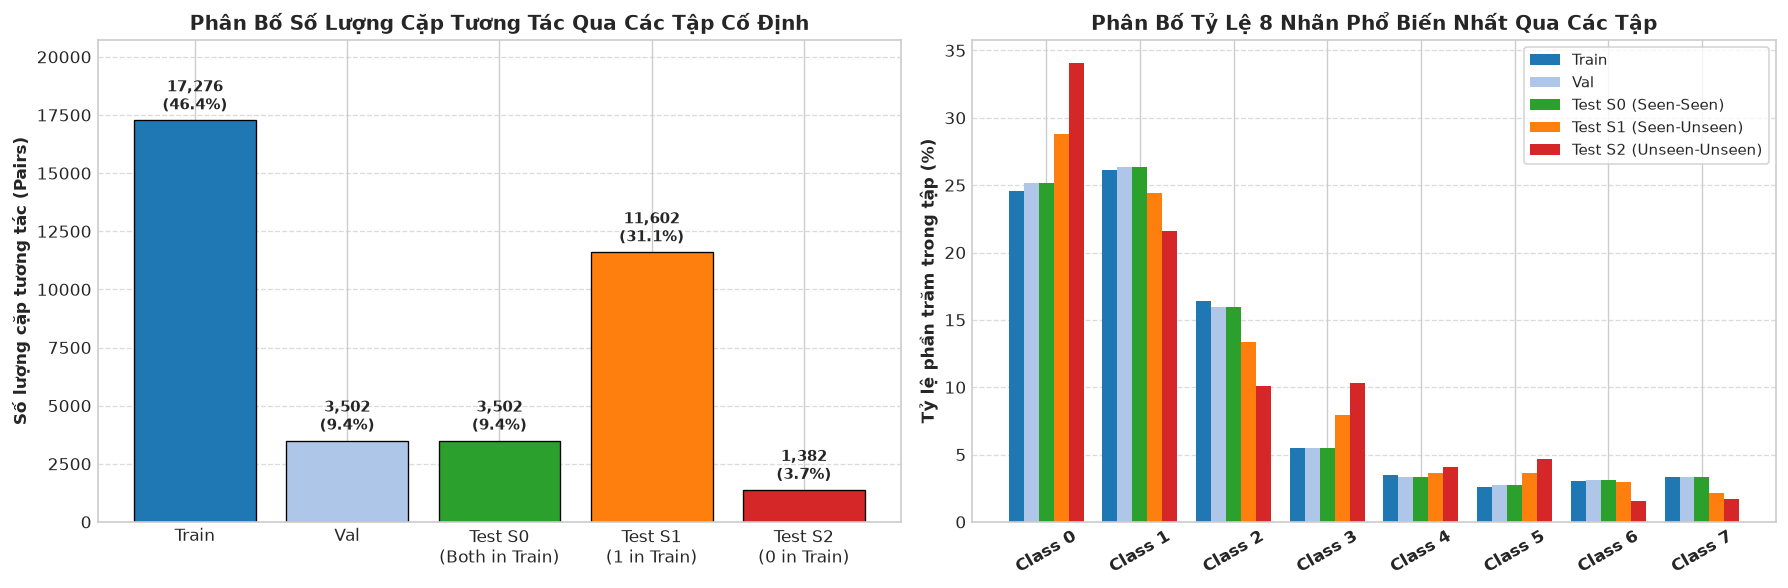

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Đồ thị 1: Phân bố số lượng mẫu qua các tập cố định
sets = ['Train', 'Val', 'Test S0\n(Both in Train)', 'Test S1\n(1 in Train)', 'Test S2\n(0 in Train)']
counts = [len(train_df), len(val_df), len(test_s0_df), len(test_s1_df), len(test_s2_df)]
colors = ['#1f77b4', '#aec7e8', '#2ca02c', '#ff7f0e', '#d62728']

bars = ax1.bar(sets, counts, color=colors, edgecolor='black', linewidth=0.8)
ax1.set_title('Phân Bố Số Lượng Cặp Tương Tác Qua Các Tập Cố Định', fontsize=12, fontweight='bold')
ax1.set_ylabel('Số lượng cặp tương tác (Pairs)', fontsize=10, fontweight='bold')
ax1.grid(axis='y', linestyle='--', alpha=0.7)

for bar in bars:
    h = bar.get_height()
    pct = h / len(df_ddi) * 100
    ax1.text(bar.get_x() + bar.get_width()/2., h + 250, f"{h:,}\n({pct:.1f}%)", ha='center', va='bottom', fontsize=9, fontweight='bold')
ax1.set_ylim(0, max(counts) * 1.2)

# Đồ thị 2: So sánh tỷ lệ 8 nhãn tương tác phổ biến nhất giữa các tập
top_labels = df_ddi['label'].value_counts().head(8).index.tolist()
plot_data = []
for lbl in top_labels:
    plot_data.append({
        'Label': f'Class {lbl}',
        'Train (%)': (train_df['label'] == lbl).mean() * 100,
        'Val (%)': (val_df['label'] == lbl).mean() * 100,
        'Test S0 (%)': (test_s0_df['label'] == lbl).mean() * 100,
        'Test S1 (%)': (test_s1_df['label'] == lbl).mean() * 100,
        'Test S2 (%)': (test_s2_df['label'] == lbl).mean() * 100,
    })
df_lbl_dist = pd.DataFrame(plot_data)

x = np.arange(len(top_labels))
w = 0.16
ax2.bar(x - 2*w, df_lbl_dist['Train (%)'], w, label='Train', color='#1f77b4')
ax2.bar(x - w, df_lbl_dist['Val (%)'], w, label='Val', color='#aec7e8')
ax2.bar(x, df_lbl_dist['Test S0 (%)'], w, label='Test S0 (Seen-Seen)', color='#2ca02c')
ax2.bar(x + w, df_lbl_dist['Test S1 (%)'], w, label='Test S1 (Seen-Unseen)', color='#ff7f0e')
ax2.bar(x + 2*w, df_lbl_dist['Test S2 (%)'], w, label='Test S2 (Unseen-Unseen)', color='#d62728')

ax2.set_title('Phân Bố Tỷ Lệ 8 Nhãn Phổ Biến Nhất Qua Các Tập', fontsize=12, fontweight='bold')
ax2.set_xticks(x)
ax2.set_xticklabels(df_lbl_dist['Label'], fontweight='bold', rotation=30)
ax2.set_ylabel('Tỷ lệ phần trăm trong tập (%)', fontsize=10, fontweight='bold')
ax2.legend(loc='upper right', frameon=True, fontsize=9)
ax2.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
vis_path = DATA2_DIR / 'data_split2_visuals.png'
plt.savefig(vis_path, dpi=150, bbox_inches='tight')
print(f"✓ Đã lưu biểu đồ trực quan hóa vào: {vis_path}")
plt.show()


## 6. Hàm Tiện Ích Tải Dữ Liệu Cố Định Sẵn Sàng Cho Huấn Luyện (Data Loader)
Hàm tiện ích `load_s0_s1_s2_data(data_dir=DATA2_DIR)` giúp dễ dàng nạp các tệp dữ liệu cố định vào các pipeline huấn luyện mô hình sâu (PyTorch, GNN, TextMLP):
- Tải trực tiếp các DataFrame `train`, `val`, `test_s0`, `test_s1`, `test_s2`.
- Tải từ điển đặc trưng thuốc `drug_features_train` và `drug_features_unseen`.


In [7]:
def load_s0_s1_s2_data(data_dir=DATA2_DIR):
    """
    Hàm chuẩn tiện ích để tải dữ liệu huấn luyện và kiểm thử cố định S0, S1, S2
    
    Parameters:
    -----------
    data_dir : Path hoặc str
        Thư mục chứa dữ liệu đã phân chia (mặc định là data2).
        
    Returns:
    --------
    data_dict : dict chứa các DataFrame tương tác và dict đặc trưng thuốc
    """
    base = Path(data_dir)
    
    train_df = pd.read_csv(base / 'train.csv')
    val_df = pd.read_csv(base / 'val.csv')
    test_s0_df = pd.read_csv(base / 'test_s0.csv')
    test_s1_df = pd.read_csv(base / 'test_s1.csv')
    test_s2_df = pd.read_csv(base / 'test_s2.csv')
    
    with open(base / 'drug_features_train.json', 'r', encoding='utf-8') as f:
        feat_train = json.load(f)
    with open(base / 'drug_features_unseen.json', 'r', encoding='utf-8') as f:
        feat_unseen = json.load(f)
        
    return {
        'train': train_df,
        'val': val_df,
        'test_s0': test_s0_df,
        'test_s1': test_s1_df,
        'test_s2': test_s2_df,
        'drug_features_train': feat_train,
        'drug_features_unseen': feat_unseen
    }

# Thử nghiệm hàm nạp dữ liệu
loaded_data = load_s0_s1_s2_data()
print("=== KIỂM TRA HÀM NẠP DỮ LIỆU load_s0_s1_s2_data ===")
print(f"• Train DF:                {loaded_data['train'].shape}")
print(f"• Val DF:                  {loaded_data['val'].shape}")
print(f"• Test S0 DF:              {loaded_data['test_s0'].shape}")
print(f"• Test S1 DF:              {loaded_data['test_s1'].shape}")
print(f"• Test S2 DF:              {loaded_data['test_s2'].shape}")
print(f"• Thuốc trong Train Feat:  {len(loaded_data['drug_features_train'])} thuốc")
print(f"• Thuốc trong Unseen Feat: {len(loaded_data['drug_features_unseen'])} thuốc")
print("✓ Hàm tải dữ liệu hoạt động chính xác và sẵn sàng tích hợp vào mô hình!")


=== KIỂM TRA HÀM NẠP DỮ LIỆU load_s0_s1_s2_data ===
• Train DF:                (17276, 7)
• Val DF:                  (3502, 7)
• Test S0 DF:              (3502, 7)
• Test S1 DF:              (11602, 7)
• Test S2 DF:              (1382, 7)
• Thuốc trong Train Feat:  456 thuốc
• Thuốc trong Unseen Feat: 114 thuốc
✓ Hàm tải dữ liệu hoạt động chính xác và sẵn sàng tích hợp vào mô hình!


### 💡 Tổng Kết & Khuyến Nghị Huấn Luyện

1. **Tuân thủ chính xác 100% định nghĩa khoa học cho các tệp cố định:**
   - **`train.csv` (17,276 cặp):** Chứa 100% 456 thuốc Seen ($V_{seen}$).
   - **`val.csv` (3,502 cặp):** Phục vụ Early Stopping, cả 2 thuốc đều nằm trong $V_{seen}$.
   - **`test_s0.csv` (3,502 cặp):** 100% cặp kiểm thử có cả 2 thuốc đều nằm trong tập `train`.
   - **`test_s1.csv` (11,602 cặp):** 100% cặp kiểm thử có đúng 1 thuốc đã biết trong `train` và 1 thuốc hoàn toàn mới.
   - **`test_s2.csv` (1,382 cặp):** 100% cặp kiểm thử có cả 2 thuốc đều hoàn toàn mới (chưa từng xuất hiện trong `train`).
   - Tổng 37,264 cặp tương tác được bảo toàn trọn vẹn, không thất thoát hay trùng lặp bất kỳ mẫu nào.

2. **Bảo vệ toàn vẹn không rò rỉ dữ liệu (Anti-Data-Leakage):**
   - Tập đặc trưng `drug_features_train.json` chỉ chứa các thuốc trong `train`. Khi xây dựng từ điển TF-IDF, bộ mã hóa BERT, hoặc chuẩn hóa StandardScaler, chỉ được `fit` trên tập này.
   - Tập đặc trưng `drug_features_unseen.json` chỉ được đưa vào ở giai đoạn `transform` hoặc inference cho $S_1$ và $S_2$.

3. **Toàn bộ dự án sử dụng trực tiếp các tệp cố định trong `data2/`:**
   - `data2/train.csv`
   - `data2/val.csv`
   - `data2/test_s0.csv`
   - `data2/test_s1.csv`
   - `data2/test_s2.csv`
   - `data2/drug_features_train.json`
   - `data2/drug_features_unseen.json`
   - `data2/drug_split_metadata.json`
